In [1]:
import pandas as pd
import networkx as nx
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import os
import tarfile
import matplotlib
import re


In [2]:
# Initializing the graph from data

nodes = pd.read_csv(
    "../data/hep-th-slacdates.tar.gz", 
    sep=r'\s+', 
    header=None, 
    names=["id", "date"], 
    dtype=str  
)


edges = pd.read_csv(
    "../data/hep-th-citations.tar.gz", 
    sep=r'\s+', 
    header=None, 
    names=["From", "To"], 
    dtype=str
)

# 3. Get unique node IDs from both columns of the edge list
node_ids = pd.unique(edges[["From", "To"]].values.ravel())

# 4. Get actual nodes listed in edge list
nodes_used = nodes[nodes["id"].isin(node_ids)].copy()

# 5. Make a directed graph smoothly
g_directed = nx.DiGraph()

# Convert the filtered nodes dataframe into a dictionary of attributes and load them
node_attributes = nodes_used.set_index("id").to_dict("index")
g_directed.add_nodes_from(node_attributes.keys())
nx.set_node_attributes(g_directed, node_attributes)

# Add the edges directly from the edge dataframe tuples
g_directed.add_edges_from(edges.itertuples(index=False, name=None))

# Print properties to verify success
print("--- GRAPH INITIALIZATION SUCCESSFUL ---")
print(f"Nodes in graph: {g_directed.number_of_nodes()}")
print(f"Edges in graph: {g_directed.number_of_edges()}")

--- GRAPH INITIALIZATION SUCCESSFUL ---
Nodes in graph: 27770
Edges in graph: 352807


In [ ]:
# Null values check
# print(f"Nulls in From column: {edges['From'].isna().sum()}")
# print(f"Nulls in To column:   {edges['To'].isna().sum()}")

Nulls in From column: 0
Nulls in To column:   0


In [ ]:
# Identify cross-listed papers (starting with "11")
# crosslisted_dates = nodes[nodes["id"].str.startswith("11", na=False)].shape[0]
# crosslisted_citations = edges[edges["From"].str.startswith("11", na=False) | edges["To"].str.startswith("11", na=False)].shape[0]
# print(f"Crosslisted rows in dates file: {crosslisted_dates}")
# print(f"Crosslisted rows in citations file: {crosslisted_citations}")

Crosslisted rows in dates file: 0
Crosslisted rows in citations file: 0


In [3]:
# Get all unique nodes active in edge pairs
edges_nodes = pd.unique(edges[["From", "To"]].values.ravel())
vertices_nodes = nodes["id"].unique()

In [ ]:
# Find structural mismatch anomalies
# problem_nodes = np.setdiff1d(edges_nodes, vertices_nodes)
# print(f"\n--- TARGETED GRAPH MATCHING DIAGNOSTIC ---")
# print(f"Total unique nodes found in edge links: {len(edges_nodes)}")
# print(f"Total unique nodes found in dates file: {len(vertices_nodes)}")
# print(f"Number of offending nodes missing metadata: {len(problem_nodes)}")


--- TARGETED GRAPH MATCHING DIAGNOSTIC ---
Total unique nodes found in edge links: 27770
Total unique nodes found in dates file: 29555
Number of offending nodes missing metadata: 0


# Summary of the network properties

In [3]:
in_deg = dict(g_directed.in_degree())
out_deg = dict(g_directed.out_degree())
in_vals, out_vals = list(in_deg.values()), list(out_deg.values())
is_strongly_connected = nx.is_strongly_connected(g_directed)
is_weakly_connected = nx.is_weakly_connected(g_directed)

scc = list(nx.strongly_connected_components(g_directed))
wcc = list(nx.weakly_connected_components(g_directed))
clustering = list(nx.clustering(g_directed).values())
# avg_path_length = nx.average_shortest_path_length(g_directed)

summary_data = {
    "Network Property": [
        "Total Vertices (Papers)", "Total Edges (Citations)", "Network Density",
        "Strongly Connected ?", "Weakly Connected ?",
        "Mean In-Degree (Citations Received)", "Max In-Degree (Top Paper)",
        "Mean Out-Degree (References Given)", "Max Out-Degree (Longest Bibliography)",
        "Total Weakly Connected Components", "Size of Largest Connected Component (WCC)",
        "Total Strongly Connected Components (Cycles)", "Size of Largest Cyclic Component (SCC)",
        "Mean Local Clustering Coefficient"
    ],
    "Value": [
        g_directed.number_of_nodes(), g_directed.number_of_edges(), f"{nx.density(g_directed):.6f}",
        is_strongly_connected, is_weakly_connected,  
        f"{np.mean(in_vals):.2f}", np.max(in_vals),
        f"{np.mean(out_vals):.2f}", np.max(out_vals),
        len(wcc), max(len(c) for c in wcc),
        len(scc), max(len(c) for c in scc),
        f"{np.mean(clustering):.4f}",
        # f"{avg_path_length:.4f}"
    ]
}

network_summary = pd.DataFrame(summary_data)
print("\n=== THE TOPOLOGICAL PROFILE OF THE NETWORK ===")
print(network_summary.to_string(index=False))


=== THE TOPOLOGICAL PROFILE OF THE NETWORK ===
                            Network Property    Value
                     Total Vertices (Papers)    27770
                     Total Edges (Citations)   352807
                             Network Density 0.000458
                        Strongly Connected ?    False
                          Weakly Connected ?    False
         Mean In-Degree (Citations Received)    12.70
                   Max In-Degree (Top Paper)     2414
          Mean Out-Degree (References Given)    12.70
       Max Out-Degree (Longest Bibliography)      562
           Total Weakly Connected Components      143
   Size of Largest Connected Component (WCC)    27400
Total Strongly Connected Components (Cycles)    20086
      Size of Largest Cyclic Component (SCC)     7464
           Mean Local Clustering Coefficient   0.1569


In [12]:
in_degree_vals = g_directed.in_degree()
prev = 0
ans = 0
paperId = ''
for id, in_deg in in_degree_vals:
    if (in_deg > prev):
        paperId = id
        ans = in_deg
        prev = in_deg

print(paperId, ans)

9711200 2414


In [14]:
out_degree_vals = g_directed.out_degree()
prev1 = 0
ans1 = 0
paperId1 = ''
for id, out_deg in out_degree_vals:
    if (out_deg > prev1):
        paperId1 = id
        ans1 = out_deg
        prev1 = out_deg

print(paperId1, ans1)

9905111 562


In [15]:
largest_wcc_nodes = max(nx.weakly_connected_components(g_directed), key=len)
g_largest_wcc = g_directed.subgraph(largest_wcc_nodes)

g_undirected_wcc = g_largest_wcc.to_undirected()

avg_path_length = nx.average_shortest_path_length(g_undirected_wcc)

print(f"Average Path Length of the wCC {avg_path_length}")

Average Path Length of the wCC 4.278680083960654


# In-Degree Plot

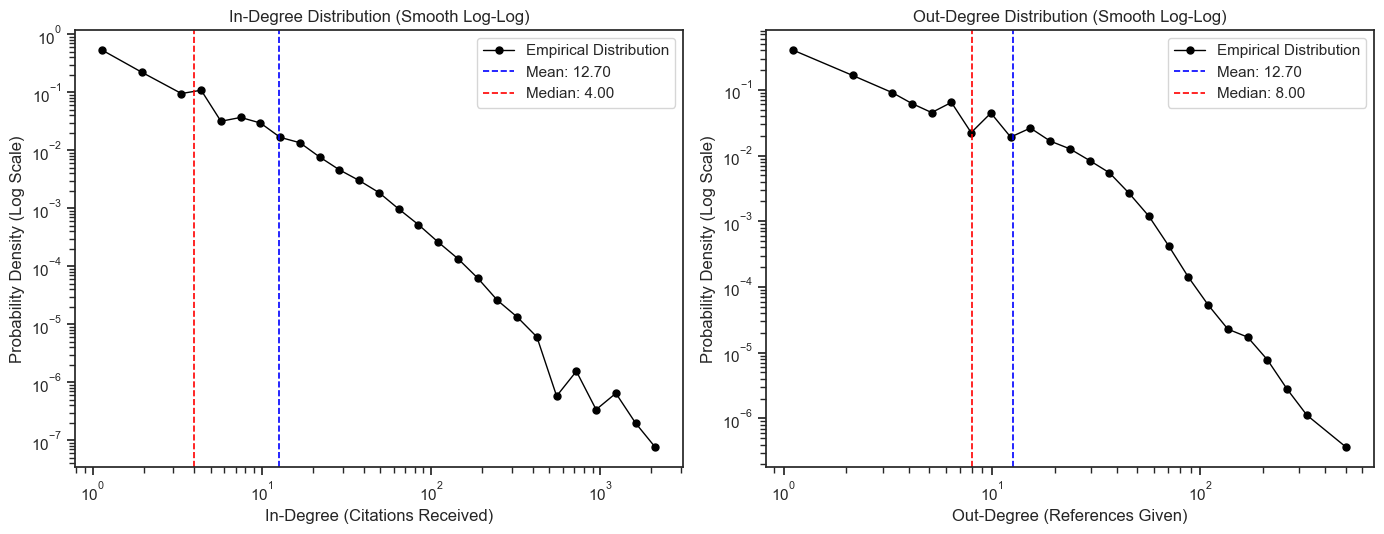

In [15]:
sns.set_theme(style="ticks")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# --- HELPER FUNCTION FOR CLEAN LOG-LINED DISTRIBUTIONS ---
def plot_clean_log_distribution(values, ax, title, xlabel):
    vals_series = pd.Series(values)
    vals_filtered = vals_series[vals_series > 0]
    
    # 1. Generate 30 clean log-spaced bins
    bins = np.logspace(np.log10(vals_filtered.min()), np.log10(vals_filtered.max()), 30)
    
    # 2. Use pandas.cut to digitize the data points into these bins
    bin_assignments = pd.cut(vals_filtered, bins=bins, include_lowest=True)
    
    # 3. Calculate the normalized density for each bin
    counts = bin_assignments.value_counts(sort=False)
    bin_widths = np.diff(bins)
    densities = counts.values / (len(vals_filtered) * bin_widths)
    
    # 4. Find the exact geometric center point of each bin for the scatter markers
    bin_centers = np.sqrt(bins[:-1] * bins[1:])
    
    # 5. Filter out empty bins to avoid drawing broken lines to log(0)
    valid = densities > 0
    
    # 6. Plot a clean continuous line with clear dot markers
    ax.plot(bin_centers[valid], densities[valid], 'o-', color='black', 
            markersize=5, linewidth=1, label='Empirical Distribution')
    
    # Structural overlays
    ax.axvline(np.mean(values), color='blue', linestyle='--', linewidth=1.2, 
               label=f"Mean: {np.mean(values):.2f}")
    ax.axvline(np.median(values), color='red', linestyle='--', linewidth=1.2, 
               label=f"Median: {np.median(values):.2f}")
    
    # Axis formatting
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Probability Density (Log Scale)")
    ax.legend()

# --- EXECUTE ON YOUR METRICS ---
plot_clean_log_distribution(in_vals, axes[0], "In-Degree Distribution (Smooth Log-Log)", "In-Degree (Citations Received)")
plot_clean_log_distribution(out_vals, axes[1], "Out-Degree Distribution (Smooth Log-Log)", "Out-Degree (References Given)")

plt.tight_layout()
plt.show()



In [4]:
# Assigning node attribute for easy extraction by year

nodes_used["year"] = pd.to_numeric(nodes_used["date"].str.slice(0,4), errors='coerce')
nx.set_node_attributes(g_directed, nodes_used.set_index("id")["year"].to_dict(), "year")

In [92]:
# os.makedirs('oslom_inputs', exist_ok = True)

# for current_year in range(1992, 2004):
#     active_ids = nodes_used[nodes_used['year'] <= current_year]["id"]
#     year_edges = edges[edges["From"].isin(active_ids) & edges["To"].isin(active_ids)]

#     filePath = f"oslom_inputs/network_{current_year}.txt"
#     year_edges.to_csv(filePath, sep = " ", header = False, index = False)

#     print(f"Exported clean snapshot for Year {current_year} -> {filePath}")


In [91]:
# for current_year in range(1995, 2004):
    
#     # Every window is now guaranteed to be exactly 4 years long
#     start_year = current_year - 3
    
#     # Filter IDs that fall strictly within this uniform 4-year bracket
#     active_ids = nodes_used[(nodes_used['year'] >= start_year) & (nodes_used['year'] <= current_year)]["id"]
    
#     # Isolate edges where BOTH the citing paper and cited paper belong to this active window
#     year_edges = edges[edges["From"].isin(active_ids) & edges["To"].isin(active_ids)]
    
#     # Construct the descriptive, symmetric file name
#     filePath = f"oslom_inputs/network_{start_year}_{current_year}.txt"
    
#     # Export to a clean, space-separated format for OSLOM
#     year_edges.to_csv(filePath, sep=" ", header=False, index=False)
    
#     print(f"Exported uniform sliding window snapshot ({start_year} to {current_year}) -> {filePath}")

In [93]:
# For extracting the abstract data

# tar = tarfile.open("../data/hep-th-abs.tar.gz", "r:gz")
# tar.extractall("../abstracts")
# tar.close()


{'9204084': 0, '9204059': 1, '9204061': 2, '9202062': 3, '9503080': 4, '9201030': 5, '9210094': 6, '9203065': 7, '9205039': 8, '9201051': 9, '9207101': 10, '9203046': 11, '9202005': 12, '9204003': 13, '9206017': 14, '9203037': 15, '9208003': 16, '9207102': 17, '9202032': 18, '9203040': 19, '9203067': 20, '9211053': 21, '9203076': 22, '9204051': 23, '9210159': 23, '9202031': 24, '9206062': 25, '9203050': 26, '9207087': 27, '9209029': 28, '9211130': 28, '9209030': 28, '9210040': 28, '9203057': 29, '9208014': 30, '9205096': 31, '9209061': 32, '9208006': 33, '9206005': 34, '9402098': 34, '9202028': 35, '9202069': 36, '9207025': 37, '9210152': 38, '9209100': 39, '9205049': 40, '9211008': 41, '9205011': 42, '9201047': 43, '9205003': 44, '9204036': 45, '9204080': 46, '9205074': 47, '9206099': 48, '9209076': 49, '9212011': 50, '9209005': 51, '9204023': 52, '9204040': 53, '9210036': 54, '9209008': 54, '9212136': 54, '9201021': 54, '9203056': 54, '9211135': 54, '9203042': 54, '9211007': 54, '920

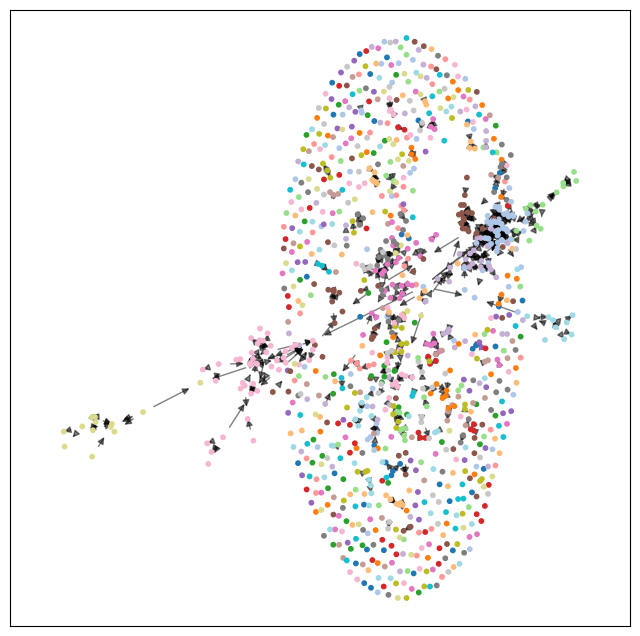

In [5]:
nodes_1992 = [id for id, year in nx.get_node_attributes(g_directed, "year").items() if year == 1992]

g_directed_1992 = g_directed.subgraph(nodes_1992)

partitions = nx.community.louvain_communities(g_directed_1992, seed=35)
# print(partitions)

community_map_1992 = {}
for community_id, community in enumerate(partitions):
    for node in community:
        community_map_1992[node] = community_id

print(community_map_1992)
node_colors = [community_map_1992[node] for node in g_directed_1992.nodes()]

cmap = matplotlib.colormaps['tab20']

plt.figure(figsize=(8,8))

pos = nx.spring_layout(g_directed_1992, seed = 35)
nx.draw_networkx_nodes(g_directed_1992, pos, node_size=10, cmap=cmap, node_color = node_colors)
nx.draw_networkx_edges(g_directed_1992, pos, alpha=0.5)
plt.show()

{'9310128': 0, '9204021': 1, '9207059': 1, '9311119': 2, '9305122': 3, '9211024': 4, '9303174': 4, '9306161': 5, '9307119': 6, '9210158': 7, '9212091': 7, '9302129': 7, '9306028': 8, '9205025': 9, '9203015': 10, '9210063': 11, '9311083': 12, '9211078': 12, '9211016': 12, '9306150': 13, '9303091': 14, '9308047': 14, '9302064': 14, '9205087': 14, '9205001': 14, '9210157': 14, '9302122': 15, '9210104': 16, '9308078': 17, '9302060': 18, '9203058': 19, '9207083': 20, '9308137': 21, '9312065': 22, '9301077': 23, '9312028': 24, '9310031': 25, '9306009': 26, '9208009': 27, '9303028': 28, '9407011': 29, '9309051': 30, '9308109': 31, '9208061': 32, '9312138': 33, '9311126': 34, '9210124': 35, '9309035': 36, '9308087': 37, '9307095': 37, '9212048': 38, '9209112': 39, '9309060': 40, '9310195': 41, '9211085': 42, '9301126': 43, '9302090': 43, '9201002': 43, '9306098': 43, '9312067': 43, '9308003': 43, '9212141': 43, '9306022': 43, '9311095': 43, '9206024': 43, '9205086': 43, '9312019': 43, '9308059

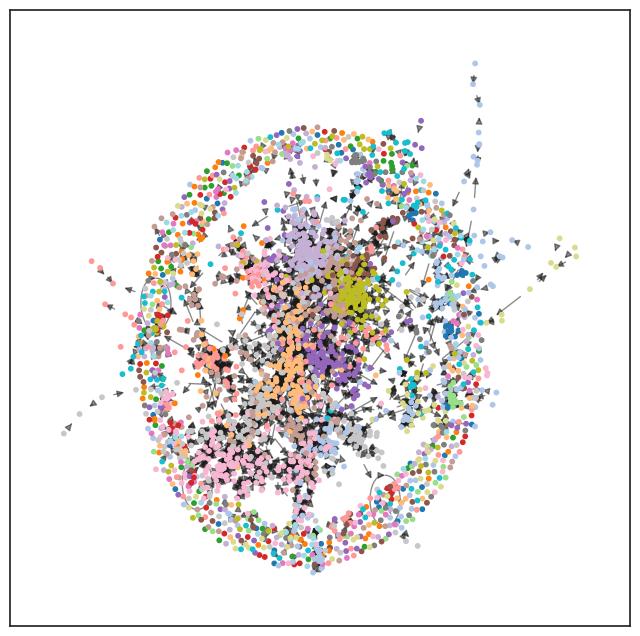

In [ ]:
nodes_1993 = [id for id, year in nx.get_node_attributes(g_directed, "year").items() if year <= 1993]
# print(nodes_1993)

g_directed_1993 = g_directed.subgraph(nodes_1993)
partitions_1993 = nx.community.louvain_communities(g_directed_1993, seed=35)
# print(partitions_1993)

community_map_1993 = {}
for community_id, community in enumerate(partitions_1993):
    for node in community:
        community_map_1993[node] = community_id

print(community_map_1993)
node_colors = [community_map_1993[node] for node in g_directed_1993.nodes()]

cmap = matplotlib.colormaps['tab20']

plt.figure(figsize=(8,8))

pos = nx.spring_layout(g_directed_1993, seed = 35)
nx.draw_networkx_nodes(g_directed_1993, pos, node_size=10, cmap=cmap, node_color = node_colors)
nx.draw_networkx_edges(g_directed_1993, pos, alpha=0.5)
plt.show()

In [6]:
comms_data = {}

for i in range(0, len(partitions)):
    comms_data[f"Community-{i}"] = list(partitions[i])

print(len(comms_data), comms_data)

681 {'Community-0': ['9204084'], 'Community-1': ['9204059'], 'Community-2': ['9204061'], 'Community-3': ['9202062'], 'Community-4': ['9503080'], 'Community-5': ['9201030'], 'Community-6': ['9210094'], 'Community-7': ['9203065'], 'Community-8': ['9205039'], 'Community-9': ['9201051'], 'Community-10': ['9207101'], 'Community-11': ['9203046'], 'Community-12': ['9202005'], 'Community-13': ['9204003'], 'Community-14': ['9206017'], 'Community-15': ['9203037'], 'Community-16': ['9208003'], 'Community-17': ['9207102'], 'Community-18': ['9202032'], 'Community-19': ['9203040'], 'Community-20': ['9203067'], 'Community-21': ['9211053'], 'Community-22': ['9203076'], 'Community-23': ['9204051', '9210159'], 'Community-24': ['9202031'], 'Community-25': ['9206062'], 'Community-26': ['9203050'], 'Community-27': ['9207087'], 'Community-28': ['9209029', '9211130', '9209030', '9210040'], 'Community-29': ['9203057'], 'Community-30': ['9208014'], 'Community-31': ['9205096'], 'Community-32': ['9209061'], 'Com

In [94]:
data_1993 = {}

for i in range(0, len(partitions_1993)):
    data_1993[f"Community-{i}"] = list(partitions_1993[i])

print(len(data_1993), data_1993)

821 {'Community-0': ['9310128'], 'Community-1': ['9204021', '9207059'], 'Community-2': ['9311119'], 'Community-3': ['9305122'], 'Community-4': ['9211024', '9303174'], 'Community-5': ['9306161'], 'Community-6': ['9307119'], 'Community-7': ['9210158', '9212091', '9302129'], 'Community-8': ['9306028'], 'Community-9': ['9205025'], 'Community-10': ['9203015'], 'Community-11': ['9210063'], 'Community-12': ['9311083', '9211078', '9211016'], 'Community-13': ['9306150'], 'Community-14': ['9303091', '9308047', '9302064', '9205087', '9205001', '9210157'], 'Community-15': ['9302122'], 'Community-16': ['9210104'], 'Community-17': ['9308078'], 'Community-18': ['9302060'], 'Community-19': ['9203058'], 'Community-20': ['9207083'], 'Community-21': ['9308137'], 'Community-22': ['9312065'], 'Community-23': ['9301077'], 'Community-24': ['9312028'], 'Community-25': ['9310031'], 'Community-26': ['9306009'], 'Community-27': ['9208009'], 'Community-28': ['9303028'], 'Community-29': ['9407011'], 'Community-30'

In [7]:
# Jaccard Similarity function

def Jaccard_Similarity(old, new):
    A = set(old)
    B = set(new)

    C = A.intersection(B)
    D = A.union(B)

    return (float(len(C))) / (float(len(D)));

In [8]:
# Create a map which will note down the index from 0 for all the papers
paperId_map = {}
nodes_1992.sort()
for i in range(0, len(nodes_1992)):
    paperId_map[nodes_1992[i]] = i

print(paperId_map)

{'9201001': 0, '9201002': 1, '9201003': 2, '9201004': 3, '9201005': 4, '9201006': 5, '9201007': 6, '9201008': 7, '9201014': 8, '9201015': 9, '9201016': 10, '9201017': 11, '9201019': 12, '9201021': 13, '9201024': 14, '9201026': 15, '9201027': 16, '9201028': 17, '9201029': 18, '9201030': 19, '9201031': 20, '9201032': 21, '9201033': 22, '9201034': 23, '9201035': 24, '9201036': 25, '9201037': 26, '9201039': 27, '9201040': 28, '9201041': 29, '9201042': 30, '9201044': 31, '9201045': 32, '9201047': 33, '9201048': 34, '9201049': 35, '9201050': 36, '9201051': 37, '9201052': 38, '9201054': 39, '9201056': 40, '9201058': 41, '9201059': 42, '9201061': 43, '9201062': 44, '9201063': 45, '9201064': 46, '9201065': 47, '9201066': 48, '9201067': 49, '9201068': 50, '9201069': 51, '9201070': 52, '9201071': 53, '9201072': 54, '9201074': 55, '9201077': 56, '9201078': 57, '9201080': 58, '9202001': 59, '9202002': 60, '9202003': 61, '9202004': 62, '9202005': 63, '9202006': 64, '9202007': 65, '9202008': 66, '920

In [ ]:
# Tracking communities framework

for community_id1, nodes1 in data_1993.items():
    for community_id2, nodes2 in comms_data.items():
        sim = Jaccard_Similarity(nodes2, nodes1)
        if sim != 0 and sim >= 0.5:
            print(f'Old {community_id2} is similar to new {community_id1} by a measure of {sim}')


Old Community-5 is similar to new Community-1 by a measure of 1.0
Old Community-8 is similar to new Community-4 by a measure of 0.5
Old Community-434 is similar to new Community-7 by a measure of 0.6666666666666666
Old Community-24 is similar to new Community-9 by a measure of 1.0
Old Community-25 is similar to new Community-10 by a measure of 1.0
Old Community-30 is similar to new Community-11 by a measure of 1.0
Old Community-33 is similar to new Community-12 by a measure of 0.6666666666666666
Old Community-418 is similar to new Community-14 by a measure of 0.5
Old Community-47 is similar to new Community-15 by a measure of 1.0
Old Community-49 is similar to new Community-16 by a measure of 1.0
Old Community-54 is similar to new Community-19 by a measure of 1.0
Old Community-57 is similar to new Community-20 by a measure of 1.0
Old Community-59 is similar to new Community-23 by a measure of 1.0
Old Community-92 is similar to new Community-30 by a measure of 1.0
Old Community-96 is si

## Trying to implement COIN model for 1992 data

Membership matrix

In [9]:
n = len(nodes_1992) # no. of papers (rows)
m = len(partitions) # no. of communities (columns)

In [10]:
# Membership matrix for 1992

# n --> nodes; m --> communities 
# n = 1051; m = 681

membership_1992 = np.zeros((n, m), dtype=int)

for paperId, x in paperId_map.items():
    y = community_map_1992.get(paperId)
    # print(y)
    membership_1992[x][y] = 1

print(membership_1992.sum())

# Membership matrix for 1992 created

1051


Centrality Tensor

In [11]:
# Creating a centrality tensor for 1992

# Centrality tensor is a completely different matrix from membership matrix. 
# Hence a slight modification is that, instead of author i,
# I will be using the paperId itself and try implementing COIN model.

centrality_tensor = np.zeros((n, m, m), dtype=int)

for citing, cited in g_directed_1992.edges():
    paperId = paperId_map.get(cited)
    u = int(community_map_1992.get(cited))
    v = int(community_map_1992.get(citing))

    centrality_tensor[paperId, u, v] += 1


In [12]:
print(centrality_tensor.sum(), len(g_directed_1992.edges()))

535 535


Impact Matrix

In [ ]:
numerator = np.einsum('xu,xuv->uv', membership_1992, centrality_tensor)

In [14]:
numerator.shape

(681, 681)

In [18]:
community_sizes = membership_1992.sum(axis=0)
community_sizes.shape

(681,)

In [22]:
# Impact Matrix

J = numerator / community_sizes[:, None]
J.shape

(681, 681)

In [23]:
print(J)

[[0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 ...
 [0.         0.         0.         ... 1.11111111 0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]]


# Working on Abstract Data

In [2]:
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\yadne\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\yadne\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\yadne\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\yadne\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [3]:
# pre-processing function for SciBERT type models

def getTitleAndAbstract(text):

    # text = re.sub(r'\n', ' ', text)

    title = re.search(r'Title:\s*(.*)', text)
    sections = text.split('\\\\')
    abstract = sections[-2] if len(sections) > 2 else ""

    abstract_cleaned = re.sub(r'\n', ' ', abstract)

    return [f'{title.group(1).strip()}. {abstract_cleaned.strip()}'.strip()]



In [4]:
# pre-processing function for LDA type models

def lda_embeddings(text):

    # for excluding other unnecessary metadata like 
    # Journal Ref:, Date:, From:, etc. 
     
    title = re.search(r'Title:\s*(.*)', text)
    sections = text.split('\\\\')
    abstract = sections[-2] if len(sections) > 2 else ""
    abstract_cleaned = re.sub(r'\n', ' ', abstract)

    text = title.group(1).strip() + '\n' + abstract_cleaned.strip()

    # to lowercase
    text = text.lower()

    # remove latex math expressions
    text = re.sub(r'\$.*?\$', ' ', text)

    # remove latex commands
    text = re.sub(r'\\[A-Za-z]+', ' ', text)

    # remove punctuations
    text = re.sub(r'[^\w\s]', ' ', text)

    # remove standalone numbers
    text = re.sub(r'\b\d+\b', ' ', text)

    # remove underscores
    text = re.sub(r'_+', ' ', text)

    # correcting whitespaces
    text = re.sub(r'\s+', ' ', text)

    # tokenization
    tokens = word_tokenize(text)

    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words and len(word) > 2
    ]

    return tokens



In [7]:
# Storing Abstract data in structured format for different models 
# Ex: LDA (require processing), SciBERT (Entire sentences are required for understanding context), etc.

papers_data = []
directory = '../abstracts/1992'

for file in os.listdir(directory):
    filename = os.fsdecode(file)
    with open(f'{directory}/{filename}') as f:
    
        text = f.read()
        
        scibert_data = getTitleAndAbstract(text)
        # print(scibert_data)

        embeddings = lda_embeddings(text)
        # print(embeddings)

        paper_id = re.search(r'Paper:\s*hep-th/(\d{7})', text)
        title = re.search(r'Title:\s*(.*)', text)
        subject = re.search(r'Subj-class:\s*(.*)', text) 

        papers_data.append({
            'paper_id': paper_id.group(1).strip(),
            'year': 1992,
            'title': title.group(1).strip() if title else "",
            'subject': subject.group(1).strip() if subject else "",
            'scibert_data': scibert_data,
            'embeddings': embeddings
        })


df_1992 = pd.DataFrame(papers_data)
df_1992.head()


,paper_id,year,title,subject,scibert_data,embeddings
0,9201001,1992,Combinatorics of the Modular Group II: the Kon...,High Energy Physics - Theory; Quantum Algebra,[Combinatorics of the Modular Group II: the Ko...,"[combinatorics, modular, group, kontsevich, in..."
1,9201002,1992,Inomogeneous Quantum Groups as Symmetries of P...,,[Inomogeneous Quantum Groups as Symmetries of ...,"[inomogeneous, quantum, group, symmetry, phono..."
2,9201003,1992,"Intersection Theory, Integrable Hierarchies an...",,"[Intersection Theory, Integrable Hierarchies a...","[intersection, theory, integrable, hierarchy, ..."
3,9201004,1992,The Heterotic Green-Schwarz Superstring on an ...,,[The Heterotic Green-Schwarz Superstring on an...,"[heterotic, green, schwarz, superstring, super..."
4,9201005,1992,Ward Identities in Two-Dimensional String Theory,,[Ward Identities in Two-Dimensional String The...,"[ward, identity, two, dimensional, string, the..."


In [9]:
df_1992.to_parquet('papers1992.paraquet')